# Т-Банк: Воронка авиабилетов

Задача исследования - изучить клиентские сессии сервиса Авиа и особенности данных, влияющие на настройку AutoML для прогноза успешной покупки. Исходный файл содержит экранные события, а не готовую таблицу с одной строкой на сессию; целевой исход необходимо определять на уровне `session_id`.

Источник: DANO, описание «Воронка авиабилетов». Результаты исследования приведены в `EDA_tbank_avia_funnel.md`.

Для воспроизведения необходим файл [dano_dataset_avia_hashed_corrected_s.xlsx](https://docs.google.com/spreadsheets/d/1upjVtIJaSdl4Rn5jgCV6N1KOq0SqxHEf/edit?usp=drive_link&ouid=104970778427981791604&rtpof=true&sd=true), размещённый рядом с ноутбуком. Используются `pandas`, `numpy`, `matplotlib` и стандартные модули Python для чтения XLSX. Ячейки выполняются последовательно сверху вниз.

## 1. Первичный анализ

Проверяются размер таблицы, типы полей, уникальность идентификаторов и полнота данных. Единица исходного наблюдения - посещение экрана в рамках сессии.

In [1]:
from pathlib import Path
from zipfile import ZipFile
from xml.etree import ElementTree as ET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

path = Path("dano_dataset_avia_hashed_corrected_s.xlsx")
if not path.is_file():
    raise FileNotFoundError(f"Не найден исходный файл: {path.name}")

def read_xlsx(path):
    # Потоковое чтение исходного XLSX без его распаковки и дополнительных библиотек.
    ns = "{http://schemas.openxmlformats.org/spreadsheetml/2006/main}"
    with ZipFile(path) as archive:
        shared = []
        with archive.open("xl/sharedStrings.xml") as source:
            for _, element in ET.iterparse(source, events=("end",)):
                if element.tag == ns + "si":
                    shared.append("".join(node.text or "" for node in element.iter(ns + "t")))
                    element.clear()
        rows = []
        with archive.open("xl/worksheets/sheet1.xml") as source:
            for _, element in ET.iterparse(source, events=("end",)):
                if element.tag == ns + "row":
                    row = [None] * 22
                    for cell in element.findall(ns + "c"):
                        value = cell.findtext(ns + "v")
                        if value is not None:
                            col = ord(cell.get("r")[0]) - ord("A")
                            row[col] = shared[int(value)] if cell.get("t") == "s" else value
                    rows.append(row)
                    element.clear()
    result = pd.DataFrame(rows[1:], columns=rows[0])
    numeric = ["client_start_year", "client_avia_user_start_year", "client_segment",
               "client_avia_orders", "client_gmv", "session_purchase_price",
               "session_purchase_tickets_num"]
    for col in numeric:
        result[col] = pd.to_numeric(result[col], errors="coerce")
    for col in ("session_start_dt", "screen_dttm"):
        result[col] = pd.to_datetime(result[col], errors="coerce")
    return result

data = read_xlsx(path)
print("Размер таблицы:", data.shape)
display(data.head(3))
display(data.dtypes.astype(str).value_counts().rename_axis("Тип").to_frame("Столбцов"))

Размер таблицы: (244345, 22)


,session_start_dt,device_platform,client_start_year,client_id,session_id,session_source,session_channel,screen_nm,screen_dttm,client_avia_user_start_year,...,client_gmv,session_purchase_price,session_purchase_tickets_num,session_purchase_tickets_sourse,session_purchase_status,session_purchase_tickets_airline,session_purchase_tickets_departure,session_purchase_tickets_arrival,session_purchase_tickets_luggage_flg,session_purchase_tickets_class_of_service
0,2025-08-11,android,2022.0,1ced90f0cbf7673a49e1f06035a20c2d31bd2876e768f2...,168e64115c5eb71efa3f2ffb59a38a04f182540de70312...,Контент-каналы,Сторис,Оффер,2025-08-11 13:05:44.638,2025,...,27427.476667,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2025-04-10,ios,2016.0,707572ff842ece6fd9c6ab59c5f7d7309de18ae153995b...,a1e18971d51f0e7699396daa17b8373dd2bddec4ffa2da...,Неизвестно,Неизвестно,Оффер,2025-04-10 23:55:10.936,2024,...,72363.028889,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2025-06-05,ios,2025.0,514278f8446c5920e20faddc6aa5b03cc8fa784aa9be9a...,f29b5c0c7391fb9aee4bb47d9dab77d1161e1eec5b108f...,SEO,Bing,Выдача,2025-06-05 10:23:44.627,2025,...,6645.640000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Столбцов
Тип,
str,13
float64,4
int64,3
datetime64[us],2


In [2]:
structure = pd.Series({
    "Строк": len(data),
    "Столбцов": data.shape[1],
    "Уникальных сессий": data["session_id"].nunique(),
    "Уникальных клиентов": data["client_id"].nunique(),
    "Полных дубликатов": int(data.duplicated().sum()),
    "Сессий с несколькими client_id": int(data.groupby("session_id")["client_id"].nunique().gt(1).sum()),
    "Сессий с несколькими session_start_dt": int(data.groupby("session_id")["session_start_dt"].nunique().gt(1).sum()),
}, name="Значение")
display(structure.to_frame())
print("Начало сессий:", data["session_start_dt"].min().date(), "-", data["session_start_dt"].max().date())
print("Время событий:", data["screen_dttm"].min(), "-", data["screen_dttm"].max())

,Значение
Строк,244345
Столбцов,22
Уникальных сессий,38561
Уникальных клиентов,1900
Полных дубликатов,0
Сессий с несколькими client_id,0
Сессий с несколькими session_start_dt,0


Начало сессий: 2025-01-01 - 2025-09-30
Время событий: 2025-01-01 00:34:38.338000 - 2025-10-01 00:46:46.808000


## 2. Повторные сессии и клиенты

Анализируются число экранных событий на сессию и повторяемость клиентов. Независимое разбиение строк исходного Excel недопустимо для сессионной задачи.

,Значение
Сессий с несколькими событиями,34522.0
Медиана событий на сессию,4.0
90-й процентиль событий на сессию,13.0
Максимум событий на сессию,405.0
Клиентов с несколькими сессиями,1900.0
Медиана сессий на клиента,15.0
Максимум сессий на клиента,148.0


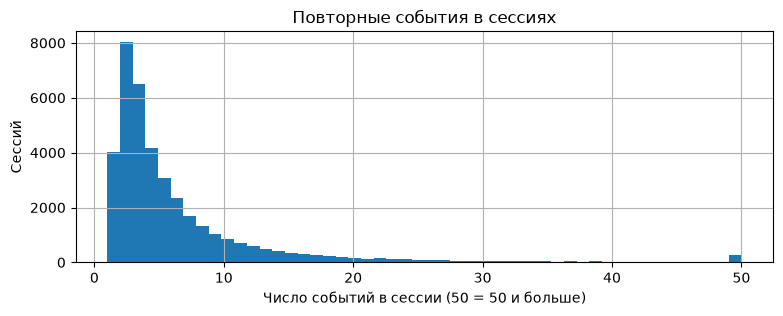

In [3]:
session_counts = data.groupby("session_id").size()
client_sessions = data[["client_id", "session_id"]].drop_duplicates().groupby("client_id").size()
repeat_stats = pd.Series({
    "Сессий с несколькими событиями": int(session_counts.gt(1).sum()),
    "Медиана событий на сессию": int(session_counts.median()),
    "90-й процентиль событий на сессию": float(session_counts.quantile(.90)),
    "Максимум событий на сессию": int(session_counts.max()),
    "Клиентов с несколькими сессиями": int(client_sessions.gt(1).sum()),
    "Медиана сессий на клиента": int(client_sessions.median()),
    "Максимум сессий на клиента": int(client_sessions.max()),
}, name="Значение")
display(repeat_stats.to_frame())
fig, ax = plt.subplots(figsize=(9, 3))
session_counts.clip(upper=50).hist(bins=50, ax=ax)
ax.set(xlabel="Число событий в сессии (50 = 50 и больше)",
       ylabel="Сессий", title="Повторные события в сессиях")
plt.show()

## 3. Целевое событие и неоднозначные исходы

Подтверждённая покупка задаётся наличием `session_purchase_status = 'Успешные'` хотя бы в одном событии сессии. Отдельно проверяется наличие цены покупки без такого статуса.

In [4]:
data["has_success"] = data["session_purchase_status"].eq("Успешные")
data["has_price"] = data["session_purchase_price"].notna()
by_session = data.groupby("session_id", sort=False)
sessions = by_session.agg(
    client_id=("client_id", "first"),
    session_start_dt=("session_start_dt", "first"),
    device_platform=("device_platform", "first"),
    session_source=("session_source", "first"),
    session_channel=("session_channel", "first"),
    client_segment=("client_segment", "first"),
    client_avia_orders=("client_avia_orders", "first"),
    client_gmv=("client_gmv", "first"),
    event_count=("screen_nm", "size"),
    confirmed_success=("has_success", "max"),
    has_price=("has_price", "max"),
    distinct_prices=("session_purchase_price", "nunique"),
)
sessions["ambiguous_price"] = sessions["has_price"] & ~sessions["confirmed_success"]
sessions["no_confirmed_outcome"] = ~sessions["has_price"] & ~sessions["confirmed_success"]
target_summary = pd.Series({
    "Сессий всего": len(sessions),
    "Сессий с подтверждённой покупкой": int(sessions["confirmed_success"].sum()),
    "Доля подтверждённых покупок, %": round(100 * sessions["confirmed_success"].mean(), 2),
    "Сессий с ценой, но без статуса": int(sessions["ambiguous_price"].sum()),
    "Сессий без подтверждения и цены": int(sessions["no_confirmed_outcome"].sum()),
    "Сессий с несколькими различными ценами": int(sessions["distinct_prices"].gt(1).sum()),
    "Строк со статусом 'Успешные'": int(data["has_success"].sum()),
    "Строк с ценой без статуса успеха": int((data["has_price"] & ~data["has_success"]).sum()),
}, name="Значение")
display(target_summary.to_frame())

,Значение
Сессий всего,38561.00
Сессий с подтверждённой покупкой,2364.00
"Доля подтверждённых покупок, %",6.13
"Сессий с ценой, но без статуса",143.00
Сессий без подтверждения и цены,36054.00
Сессий с несколькими различными ценами,17.00
Строк со статусом 'Успешные',2622.00
Строк с ценой без статуса успеха,167.00


## 4. Экранная воронка и последовательность событий

Сравниваются посещения экранов и их наличие в сессиях. Число событий не равно числу независимых пользователей или покупок, а последовательность экранов может быть нелинейной.

,Событий,Сессий с экраном
screen_nm,,
Выдача,110591,34324
Оффер,53172,17709
Поиск,59525,37756
Покупка бэк,2789,2507
Покупка фронт,2432,2253
Чекаут,15836,6469


Подтверждённые покупки по экранам:


,Строк
screen_nm,
Покупка бэк,2622


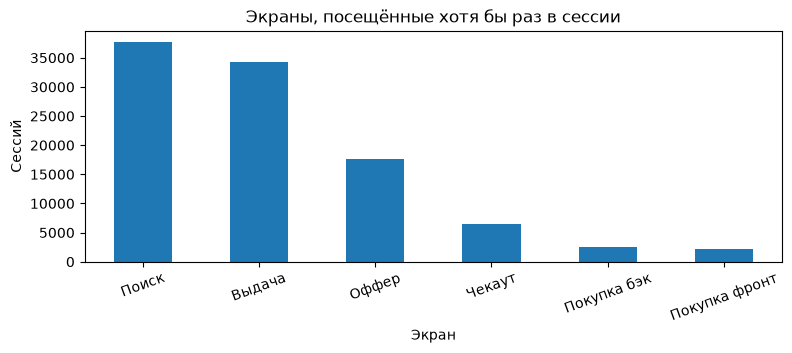

In [5]:
screen_rows = data["screen_nm"].value_counts()
screen_sessions = data.groupby("screen_nm")["session_id"].nunique()
screen_table = pd.DataFrame({"Событий": screen_rows, "Сессий с экраном": screen_sessions})
display(screen_table)
print("Подтверждённые покупки по экранам:")
display(data.loc[data["has_success"], "screen_nm"].value_counts().to_frame("Строк"))
ax = screen_sessions.sort_values(ascending=False).plot.bar(figsize=(9, 3), rot=20)
ax.set(xlabel="Экран", ylabel="Сессий", title="Экраны, посещённые хотя бы раз в сессии")
plt.show()

In [6]:
date_gap = (data["screen_dttm"].dt.normalize() - data["session_start_dt"].dt.normalize()).dt.days
screen_time_summary = pd.Series({
    "Событий до календарного дня начала сессии": int(date_gap.lt(0).sum()),
    "Событий на следующий день или позже": int(date_gap.gt(0).sum()),
    "Событий спустя два дня": int(date_gap.eq(2).sum()),
    "Событий раньше начала дня сессии": int(data["screen_dttm"].lt(data["session_start_dt"]).sum()),
    "Повторных сочетаний (session_id, screen_nm, screen_dttm)": int(data.duplicated(["session_id", "screen_nm", "screen_dttm"]).sum()),
}, name="Значение")
display(screen_time_summary.to_frame())

,Значение
Событий до календарного дня начала сессии,0
Событий на следующий день или позже,4724
Событий спустя два дня,2
Событий раньше начала дня сессии,0
"Повторных сочетаний (session_id, screen_nm, screen_dttm)",0


## 5. Пропуски и специальные значения

Изучаются обычные пропуски и специальное значение `Неизвестно`. Поля покупки по описанию заполняются только при успешной операции, поэтому их высокая пустота сама по себе не означает дефект данных.

In [7]:
missing = pd.DataFrame({"Пропусков": data.isna().sum()})
missing["Доля, %"] = (100 * missing["Пропусков"] / len(data)).round(2)
display(missing.sort_values("Пропусков", ascending=False))
print("Платформы устройств:")
display(data["device_platform"].value_counts(dropna=False).to_frame("Строк"))
unknown = pd.DataFrame({
    "Поле": ["session_source", "session_channel"],
    "Значений 'Неизвестно'": [int(data[col].eq("Неизвестно").sum()) for col in ("session_source", "session_channel")],
})
unknown["Доля, %"] = (100 * unknown["Значений 'Неизвестно'"] / len(data)).round(2)
display(unknown)

,Пропусков,"Доля, %"
session_purchase_tickets_luggage_flg,241723,98.93
session_purchase_tickets_airline,241723,98.93
session_purchase_status,241723,98.93
session_purchase_tickets_arrival,241723,98.93
session_purchase_tickets_departure,241723,98.93
session_purchase_tickets_class_of_service,241723,98.93
session_purchase_tickets_sourse,241723,98.93
session_purchase_price,241556,98.86
session_purchase_tickets_num,241556,98.86
device_platform,211,0.09


Платформы устройств:


,Строк
device_platform,
ios,137206
android,106721
NaN,211
ubuntu,207


,Поле,Значений 'Неизвестно',"Доля, %"
0,session_source,121236,49.62
1,session_channel,121236,49.62


## 6. Сегменты и источники сессий

Исходы сравниваются по сегментам, платформам и источникам. Сессия учитывается один раз; различия долей не трактуются как причинное влияние канала.

In [8]:
def summary_by(column):
    result = sessions.groupby(column, dropna=False).agg(
        Сессий=("confirmed_success", "size"),
        Подтверждённых_покупок=("confirmed_success", "sum"),
        Неоднозначных=("ambiguous_price", "sum"),
    )
    result["Доля покупок, %"] = (100 * result["Подтверждённых_покупок"] / result["Сессий"]).round(2)
    return result
print("Платформы:")
display(summary_by("device_platform"))
print("Источники:")
display(summary_by("session_source"))
print("Сегменты:")
display(summary_by("client_segment"))

Платформы:


,Сессий,Подтверждённых_покупок,Неоднозначных,"Доля покупок, %"
device_platform,,,,
android,16855,1037,64,6.15
ios,21657,1324,79,6.11
ubuntu,23,2,0,8.70
NaN,26,1,0,3.85


Источники:


,Сессий,Подтверждённых_покупок,Неоднозначных,"Доля покупок, %"
session_source,,,,
SEO,9742,584,40,5.99
Выгода,1925,118,8,6.13
Контент-каналы,7631,482,29,6.32
Неизвестно,19263,1180,66,6.13


Сегменты:


,Сессий,Подтверждённых_покупок,Неоднозначных,"Доля покупок, %"
client_segment,,,,
1,1367,76,4,5.56
2,13766,888,70,6.45
3,3777,128,18,3.39
4,13938,1001,31,7.18
5,4968,266,20,5.35
6,745,5,0,0.67


In [9]:
print("Каналы:")
display(summary_by("session_channel").sort_values("Сессий", ascending=False))
print("Клиенты, менявшие сегмент между сессиями:",
      int(sessions.groupby("client_id")["client_segment"].nunique().gt(1).sum()))

Каналы:


,Сессий,Подтверждённых_покупок,Неоднозначных,"Доля покупок, %"
session_channel,,,,
Неизвестно,19263,1180,66,6.13
Яндекс,3947,214,15,5.42
Google,3891,257,13,6.60
Сторис,3807,219,11,5.75
UTM-метки Выгоды,1925,118,8,6.13
banner,1912,137,9,7.17
email,1912,126,9,6.59
Bing,1904,113,12,5.93


Клиенты, менявшие сегмент между сессиями: 637


## 7. Числовые признаки клиента и характеристики покупки

Исследуются диапазоны признаков `client_gmv`, `client_avia_orders` и цены покупки. Необходимо учитывать, что клиентские агрегаты могут изменяться между сессиями, а источник их исторического расчёта не приведён.

In [10]:
numeric_summary = sessions[["client_gmv", "client_avia_orders"]].describe(percentiles=[.5, .9, .99]).T
numeric_summary["Пропусков"] = sessions[["client_gmv", "client_avia_orders"]].isna().sum()
display(numeric_summary)
price = data["session_purchase_price"].dropna()
price_summary = pd.Series({
    "Записей с ценой": int(price.size),
    "Минимум": float(price.min()),
    "Медиана": float(price.median()),
    "90-й процентиль": float(price.quantile(.90)),
    "Максимум": float(price.max()),
    "Нулевых цен": int(price.eq(0).sum()),
    "Отрицательных цен": int(price.lt(0).sum()),
}, name="Значение")
display(price_summary.to_frame())

,count,mean,std,min,50%,90%,99%,max,Пропусков
client_gmv,38561.0,18965.719861,17755.907064,1347.42,14308.0,35125.23875,91215.775161,280978.87,0
client_avia_orders,38561.0,10.522678,19.377340,1.00,5.0,24.00000,122.000000,414.00,0


,Значение
Записей с ценой,2789.000
Минимум,320.000
Медиана,9892.780
90-й процентиль,28259.702
Максимум,280978.870
Нулевых цен,0.000
Отрицательных цен,0.000


## 8. Временная структура и валидация

Сравнивается доля зафиксированных успешных сессий по месяцам и проверяется хронологическое разделение. Сессии одного клиента могут находиться по разные стороны границы.

,Сессий,Успешных,Неоднозначных,"Доля успеха, %"
session_start_dt,,,,
2025-01,4784,394,21,8.24
2025-02,4004,264,19,6.59
2025-03,4374,294,24,6.72
2025-04,4475,280,14,6.26
2025-05,4659,283,9,6.07
2025-06,4575,264,11,5.77
2025-07,4061,82,9,2.02
2025-08,4390,293,18,6.67
2025-09,3239,210,18,6.48


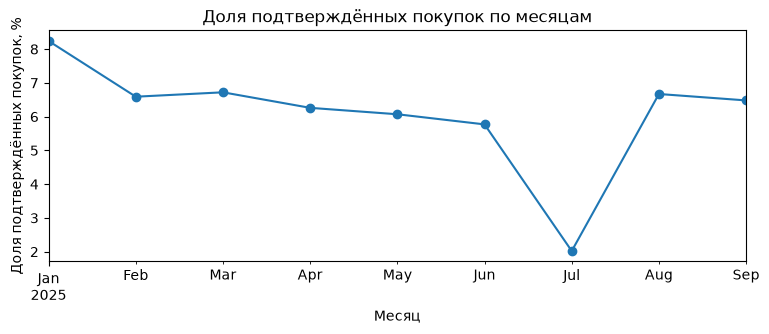

In [11]:
monthly = sessions.groupby(sessions["session_start_dt"].dt.to_period("M")).agg(
    Сессий=("confirmed_success", "size"),
    Успешных=("confirmed_success", "sum"),
    Неоднозначных=("ambiguous_price", "sum"),
)
monthly["Доля успеха, %"] = (100 * monthly["Успешных"] / monthly["Сессий"]).round(2)
display(monthly)
ax = monthly["Доля успеха, %"].plot(figsize=(9, 3), marker="o")
ax.set(xlabel="Месяц", ylabel="Доля подтверждённых покупок, %",
       title="Доля подтверждённых покупок по месяцам")
plt.show()

In [12]:
border = pd.Timestamp("2025-08-01")
train_part = sessions.loc[sessions["session_start_dt"] < border]
valid_part = sessions.loc[sessions["session_start_dt"] >= border]
validation = pd.DataFrame({
    "Часть": ["До 01.08.2025", "С 01.08.2025"],
    "Сессий": [len(train_part), len(valid_part)],
    "Подтверждённых покупок": [int(train_part["confirmed_success"].sum()), int(valid_part["confirmed_success"].sum())],
    "Неоднозначных": [int(train_part["ambiguous_price"].sum()), int(valid_part["ambiguous_price"].sum())],
    "Уникальных клиентов": [train_part["client_id"].nunique(), valid_part["client_id"].nunique()],
    "Доля успеха, %": [round(100 * train_part["confirmed_success"].mean(), 2),
                        round(100 * valid_part["confirmed_success"].mean(), 2)],
})
display(validation)
print("Общих клиентов между частями:", len(set(train_part["client_id"]) & set(valid_part["client_id"])))

,Часть,Сессий,Подтверждённых покупок,Неоднозначных,Уникальных клиентов,"Доля успеха, %"
0,До 01.08.2025,30932,1861,107,1843,6.02
1,С 01.08.2025,7629,503,36,1408,6.59


Общих клиентов между частями: 1351


## 9. Граница прогноза и доступность признаков

Для прогноза на входе в сессию недопустимы экранные события и сведения о покупке, возникшие позднее. Клиентские агрегаты могут использоваться только при подтверждении их доступности на дату сессии.

In [13]:
availability = pd.DataFrame([
    {"Группа": "Признаки сессии", "Примеры": "Устройство, источник, канал, дата начала", "Условие": "Доступны в момент входа"},
    {"Группа": "Клиентские агрегаты", "Примеры": "Сегмент, GMV, предыдущие заказы", "Условие": "Рассчитаны без будущих операций"},
    {"Группа": "Экранные события", "Примеры": "Поиск, оффер, чекаут, покупка", "Условие": "Исключить события после момента прогноза"},
    {"Группа": "Поля результата", "Примеры": "Статус, цена, маршрут, число билетов", "Условие": "Исключить как утечку цели"},
    {"Группа": "Технические идентификаторы", "Примеры": "session_id, client_id", "Условие": "Использовать для связей и разделения, не как признаки"},
])
display(availability)

,Группа,Примеры,Условие
0,Признаки сессии,"Устройство, источник, канал, дата начала",Доступны в момент входа
1,Клиентские агрегаты,"Сегмент, GMV, предыдущие заказы",Рассчитаны без будущих операций
2,Экранные события,"Поиск, оффер, чекаут, покупка",Исключить события после момента прогноза
3,Поля результата,"Статус, цена, маршрут, число билетов",Исключить как утечку цели
4,Технические идентификаторы,"session_id, client_id","Использовать для связей и разделения, не как п..."


## 10. Выводы для настройки AutoML

1. Определить единицу прогноза как сессию и агрегировать события без размножения обучающих наблюдений.
2. Уточнить момент прогноза и исключить экранные действия, появившиеся после него.
3. Формировать бинарную цель по подтверждённому статусу успеха, отдельно обрабатывать сессии с ценой без статуса.
4. Учитывать редкость подтверждённых покупок при выборе метрики по стоимости ошибок.
5. Проверять значения `Неизвестно`, пропуски, различия платформ, сегментов и каналов.
6. Для прогноза будущих сессий применять хронологическую валидацию; при работе с новыми клиентами дополнительно рассматривать групповой сценарий.
7. Не использовать поля покупки как признаки. Проверять историческую доступность клиентских агрегатов.
8. Не интерпретировать различия конверсии по сегментам или источникам как доказательство причинного влияния.